# Demo: PyTorch Forward Hooks for MoE Routing

This notebook demonstrates Issue #5: capturing expert routing probabilities from MoE models using PyTorch forward hooks.

We'll:
1. Load a Mixtral model
2. Register hooks on the MoE router layers
3. Run a forward pass
4. Inspect the captured routing data

## Setup

In [1]:
# Install dependencies (if needed)
# !pip install torch transformers -q

In [2]:
import torch
import torch.nn.functional as F
import queue
import pandas as pd
from transformers import MixtralConfig, MixtralForCausalLM, AutoTokenizer

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

PyTorch version: 2.11.0+cpu
Device: cpu


## Define Hook Infrastructure

Thread-safe buffer to collect routing data without blocking the forward pass.

In [3]:
class RoutingDataBuffer:
    """Thread-safe buffer for hook outputs."""
    def __init__(self):
        self.buffer = queue.Queue()
        
    def add(self, layer_idx, logits, probabilities, top2_indices):
        self.buffer.put({
            'layer_idx': layer_idx,
            'logits': logits.detach().cpu(),
            'probabilities': probabilities.detach().cpu(),
            'top2_indices': top2_indices.detach().cpu()
        })
        
    def get_all(self):
        results = []
        while not self.buffer.empty():
            results.append(self.buffer.get())
        return results


def create_router_hook(layer_idx, data_buffer):
    """Factory for hook callbacks."""
    def hook(module, input, output):
        logits, selected_weights, selected_indices = output
        probabilities = F.softmax(logits, dim=-1)
        top2_indices = selected_indices.int()
        data_buffer.add(layer_idx, logits, probabilities, top2_indices)
    return hook


def register_router_hooks(model, data_buffer):
    """Register hooks on all MoE router layers."""
    hook_handles = []
    for i, layer in enumerate(model.model.layers):
        router_gate = layer.mlp.gate
        handle = router_gate.register_forward_hook(create_router_hook(i, data_buffer))
        hook_handles.append(handle)
    return hook_handles

print("✓ Hook infrastructure loaded")

✓ Hook infrastructure loaded


## Load Model

For demo purposes, we use a tiny Mixtral model (4 layers, 32 hidden size). 

For production, replace with: `MixtralForCausalLM.from_pretrained("mistralai/Mixtral-8x7B-v0.1")`

In [4]:
# Use tiny toy model for speed (can replace with real Mixtral if you have GPU + memory)
config = MixtralConfig(
    num_hidden_layers=4,      # 4 layers instead of 32 for speed
    hidden_size=32,            # Tiny hidden size
    intermediate_size=64,
    num_attention_heads=4,
    num_key_value_heads=2,
    num_local_experts=8,       # Still 8 experts per layer
    num_experts_per_tok=2,     # Top-2 routing
    vocab_size=32000
)
model = MixtralForCausalLM(config)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

print(f"✓ Model loaded ({config.num_hidden_layers} layers, {config.num_local_experts} experts/layer)")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")

✓ Model loaded (4 layers, 8 experts/layer)
  Total parameters: 2,258,208


## Register Hooks & Run Forward Pass

In [5]:
# Initialize buffer and register hooks
data_buffer = RoutingDataBuffer()
handles = register_router_hooks(model, data_buffer)

print(f"✓ Registered {len(handles)} hooks (one per layer)")

# Create dummy input
batch_size, seq_len = 2, 16
input_ids = torch.randint(0, config.vocab_size, (batch_size, seq_len), device=device)

print(f"Input shape: {input_ids.shape}")

# Forward pass (hooks fire automatically)
with torch.no_grad():
    outputs = model(input_ids)

print("✓ Forward pass complete, routing data captured")

✓ Registered 4 hooks (one per layer)
Input shape: torch.Size([2, 16])
✓ Forward pass complete, routing data captured


## Inspect Captured Routing Data

In [6]:
# Collect all routing data
routing_data = data_buffer.get_all()

print(f"Captured data from {len(routing_data)} layers")
print()

# Show details for first layer
first_layer = routing_data[0]
print(f"Layer {first_layer['layer_idx']}:")
print(f"  Logits shape:        {first_layer['logits'].shape}")
print(f"  Probabilities shape: {first_layer['probabilities'].shape}")
print(f"  Top-2 indices shape: {first_layer['top2_indices'].shape}")
print()
print(f"  Logits (first 3):")
print(f"    {first_layer['logits'][:3]}")
print()
print(f"  Probabilities (first 3, sum per row):")
print(f"    {first_layer['probabilities'][:3].sum(dim=1)}")
print()
print(f"  Top-2 expert indices (first 3):")
print(f"    {first_layer['top2_indices'][:3]}")

Captured data from 4 layers

Layer 0:
  Logits shape:        torch.Size([32, 8])
  Probabilities shape: torch.Size([32, 8])
  Top-2 indices shape: torch.Size([32, 2])

  Logits (first 3):
    tensor([[ 0.2618,  0.0425,  0.0207, -0.1127,  0.0087,  0.1135,  0.0101, -0.0794],
        [ 0.0372,  0.0050,  0.0692, -0.1191,  0.0020,  0.0238, -0.0428, -0.0773],
        [-0.0873, -0.0921,  0.0415,  0.0671,  0.0420, -0.0143,  0.1261, -0.0392]])

  Probabilities (first 3, sum per row):
    tensor([1.0000, 1.0000, 1.0000])

  Top-2 expert indices (first 3):
    tensor([[0, 5],
        [2, 0],
        [6, 3]], dtype=torch.int32)


## Summary Statistics

In [7]:
# Compute expert activation frequencies across all layers
summary = []

for data in routing_data:
    layer_idx = data['layer_idx']
    top2 = data['top2_indices']
    probs = data['probabilities']
    
    # Count expert activations
    flat_indices = top2.flatten()
    unique, counts = torch.unique(flat_indices, return_counts=True)
    
    # Average probability per selected expert
    flat_probs = probs.flatten()
    sorted_probs = flat_probs[torch.argsort(flat_indices)]
    
    summary.append({
        'Layer': layer_idx,
        'Num Tokens': top2.shape[0],
        'Top Expert': int(unique[counts.argmax()]),
        'Top Expert Count': int(counts.max()),
        'Min Prob': float(probs.min()),
        'Max Prob': float(probs.max()),
        'Mean Prob': float(probs.mean())
    })

df = pd.DataFrame(summary)
print("\nExpert Activation Summary:")
print(df.to_string(index=False))


Expert Activation Summary:
 Layer  Num Tokens  Top Expert  Top Expert Count  Min Prob  Max Prob  Mean Prob
     0          32           1                12  0.097764  0.161624      0.125
     1          32           2                13  0.087989  0.159193      0.125
     2          32           5                13  0.097409  0.161531      0.125
     3          32           6                15  0.097853  0.167837      0.125


## Visualization: Expert Distribution per Layer

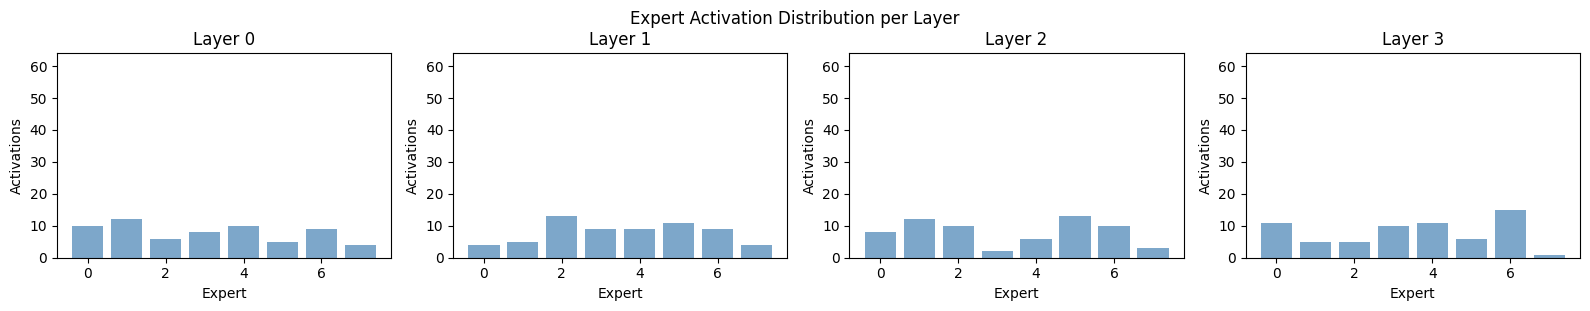

✓ Visualization complete


In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, len(routing_data), figsize=(16, 3))

for idx, data in enumerate(routing_data):
    layer_idx = data['layer_idx']
    top2 = data['top2_indices'].numpy()
    
    # Count expert activations
    expert_counts = np.bincount(top2.flatten(), minlength=config.num_local_experts)
    
    ax = axes[idx] if len(routing_data) > 1 else axes
    ax.bar(range(config.num_local_experts), expert_counts, color='steelblue', alpha=0.7)
    ax.set_title(f'Layer {layer_idx}')
    ax.set_xlabel('Expert')
    ax.set_ylabel('Activations')
    ax.set_ylim([0, top2.shape[0] * 2])  # Top-2 routing

plt.tight_layout()
plt.suptitle('Expert Activation Distribution per Layer', y=1.02)
plt.show()

print("✓ Visualization complete")

## Cleanup

In [9]:
# Remove hooks to avoid affecting subsequent forward passes
for handle in handles:
    handle.remove()

print("✓ Hooks removed")

✓ Hooks removed


## What's Next?

This demo shows the basic hook mechanics. In the actual Phase 1 pipeline (Issue #15), these hooks will be integrated into the data collection loop to capture routing probabilities for all tokens across multiple datasets.

**Key takeaways:**
- ✅ Hooks capture logits, probabilities, and top-2 expert indices
- ✅ Async queue-based collection (no blocking)
- ✅ Works on GPU or CPU
- ✅ Easy to register/unregister for each forward pass